# mzML Plotting Comparison: pyOpenMS vs. pyteomics

This notebook demonstrates how to extract and plot a specific mass spectrum from an `mzML` file using two different libraries: **pyOpenMS** and **pyteomics**.

The goal is to ensure that both methods yield identical results by keeping their loading and extraction logic completely independent.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pyopenms
from pyteomics import mzml as py_mzml

## Configuration
Set the path to your mzML file and the Target Spectrum ID (Native ID) you wish to plot.

In [2]:
# === CONFIGURATION ===
# List of mzML files to process
INPUT_FILES = [
    "/mnt/volume/nacho/data/ProCa_Anna/mzml_classII/231204_DF_ProCa_ProT001_TueL_20_LC005-2_MSV035_HT_Rep1_Slot1-20_1_324.mzML"
]

# Peptide Search Configuration (PRIORITY)
# If 'peptide_sequence' AND 'idxml_path' are set, this takes precedence over TARGET_SPECTRUM_ID.
PEPTIDE_SEARCH_CONFIG = {
    "peptide_sequence": "", 
    "idxml_path": "/mnt/volume/nacho/data/ProCa_Anna/idxml_classII/ProT001_1_pout_filtered.idXML"  # Path to idXML. MUST be provided if using peptide search.
}

# Target Spectrum ID (Native ID) to plot - FALLBACK ONLY
TARGET_SPECTRUM_ID = "index=19449"

print(f"Configured {len(INPUT_FILES)} input file(s).")

# Analysis Backend Selection
# Options: "both", "pyopenms", "pyteomics"
ANALYSIS_BACKEND = "both"


Configured 1 input file(s).


## Utility: Find Spectrum Index
Use this cell to find the Spectrum ID for a specific peptide sequence from an idXML file.

In [3]:
# === Spectrum Selection Logic ===
import os
import sys
from pathlib import Path
try:
    import pyopenms as oms
except ImportError:
    oms = None

# Initialize variables
EFFECTIVE_SPECTRUM_ID = None
SEARCH_SOURCE_INFO = ""

search_seq = PEPTIDE_SEARCH_CONFIG.get("peptide_sequence")
idxml_path = PEPTIDE_SEARCH_CONFIG.get("idxml_path")

# --- PRIORITY 1: PEPTIDE SEARCH ---
use_peptide_search = False
if search_seq and idxml_path:
    # Peptide search is requested
    if not os.path.exists(idxml_path):
        print(f"⚠️ WARNING: Configured idXML path not found: {idxml_path}")
        print("   Falling back to manual index...")
    elif not oms:
        print("⚠️ WARNING: pyOpenMS not installed. Cannot search idXML.")
        print("   Falling back to manual index...")
    else:
        use_peptide_search = True
        print(f"🔍 Searching for peptide '{search_seq}' in {Path(idxml_path).name}...")
        protein_ids = []
        peptide_ids = []
        oms.IdXMLFile().load(idxml_path, protein_ids, peptide_ids)
        
        found_spec_id = None
        for pep in peptide_ids:
            if found_spec_id: break
            for hit in pep.getHits():
                seq = hit.getSequence().toString()
                # Check if search sequence matches (robust to mods if simple substring)
                if search_seq in seq:
                    found_spec_id = pep.getMetaValue("spectrum_reference")
                    print(f"   ✅ Found match! Sequence: {seq}")
                    break
        
        if found_spec_id:
            EFFECTIVE_SPECTRUM_ID = found_spec_id
            xml_name = Path(idxml_path).name
            SEARCH_SOURCE_INFO = f"Peptide: {search_seq} | idXML: {xml_name}"
            print(f"   Using ID from idXML: {EFFECTIVE_SPECTRUM_ID}")
        else:
            print(f"❌ Peptide '{search_seq}' not found in idXML.")
            print("   Falling back to manual index...")

# --- PRIORITY 2: MANUAL INDEX (FALLBACK) ---
if not EFFECTIVE_SPECTRUM_ID:
    if TARGET_SPECTRUM_ID:
        EFFECTIVE_SPECTRUM_ID = TARGET_SPECTRUM_ID
        SEARCH_SOURCE_INFO = "Source: Manual Index"
        print(f"ℹ️ Using manual TARGET_SPECTRUM_ID: {EFFECTIVE_SPECTRUM_ID}")
    else:
        # --- FAILURE CASE ---
        error_msg = "CRITICAL ERROR: No spectrum ID could be determined.\n"
        error_msg += "1. Peptide search failed or was not configured correcty.\n"
        error_msg += "2. Manual TARGET_SPECTRUM_ID is missing."
        # Raise error to stop execution
        raise ValueError(error_msg)

print(f"\n🎯 FINAL SELECTION: {EFFECTIVE_SPECTRUM_ID}")


ℹ️ Using manual TARGET_SPECTRUM_ID: index=19449

🎯 FINAL SELECTION: index=19449


## Method 1: pyOpenMS
This function loads the file using `pyopenms.MSExperiment` and iterates to find the spectrum with the matching native ID.

In [4]:
def get_data_pyopenms(file_path, target_id):
    """
    Loads mzML, finds target spectrum (assumed MS2), and its precursor MS1.
    Returns a dict: {'MS1': (mz, int, id), 'MS2': (mz, int, id)}
    """
    print(f"[pyOpenMS] Loading {file_path}...")
    exp = pyopenms.MSExperiment()
    pyopenms.MzMLFile().load(file_path, exp)
    
    target_idx = -1
    # Find target index
    for i, spec in enumerate(exp):
        if spec.getNativeID() == target_id:
            target_idx = i
            break
            
    if target_idx == -1:
        raise ValueError(f"Spectrum {target_id} not found in PyOpenMS.")
        
    results = {}
    
    # Get Target Spectrum (MS2)
    target_spec = exp[target_idx]
    if target_spec.getMSLevel() == 2:
        mz, inte = target_spec.get_peaks()
        results['MS2'] = (mz, inte, target_spec.getNativeID())
        
        # Find preceding MS1
        for i in range(target_idx - 1, -1, -1):
            if exp[i].getMSLevel() == 1:
                mz1, inte1 = exp[i].get_peaks()
                results['MS1'] = (mz1, inte1, exp[i].getNativeID())
                break
    else:
        # Target is MS1
        mz, inte = target_spec.get_peaks()
        results['MS1'] = (mz, inte, target_spec.getNativeID())
        
    return results


## Method 2: pyteomics
This function loads the file using `pyteomics.mzml.read` and retrieves the spectrum by ID.

In [5]:
def get_data_pyteomics(file_path, target_id):
    """
    Loads via pyteomics, finds target MS2 and precursor MS1.
    Returns a dict: {'MS1': (mz, int, id), 'MS2': (mz, int, id)}
    """
    print(f"[pyteomics] Loading {file_path}...")
    results = {}
    
    with py_mzml.read(file_path, use_index=True) as reader:
        # Get target
        try:
            spec = reader.get_by_id(target_id)
        except KeyError:
             raise ValueError(f"Spectrum {target_id} not found in Pyteomics.")
             
        # Check MS level
        if spec['ms level'] == 2:
            results['MS2'] = (spec['m/z array'], spec['intensity array'], spec['id'])
            
            # Find precursor MS1
            # Scan index is available in 'index' attribute (0-based order stored by pyteomics indexing)
            # We can use reader[index-1] to search backwards if indexed
            # NOTE: reader.get_by_index or reader[i] access by 0-based index in file order
            if 'index' in spec:
                 current_idx = spec['index']
                 for i in range(current_idx - 1, -1, -1):
                     try:
                         prev_spec = reader[i]
                         if prev_spec['ms level'] == 1:
                             results['MS1'] = (prev_spec['m/z array'], prev_spec['intensity array'], prev_spec['id'])
                             break
                     except IndexError: 
                         break
        else:
            # Target is MS1
            results['MS1'] = (spec['m/z array'], spec['intensity array'], spec['id'])
            
    return results


## Comparison & Plotting
Now we run both methods and compare the results numerically and visually.

In [6]:
def plot_spectra(data, source_name, file_name, spectrum_id):
    """Plots MS1 and MS2 for a single backend."""
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    ax = ax.flatten()
    levels = ['MS1', 'MS2']
    colors = {'pyOpenMS': 'blue', 'pyteomics': 'red'}
    color = colors.get(source_name, 'green')
    
    for i, level in enumerate(levels):
        level_data = data.get(level)
        if level_data:
            mz, inte, sid = level_data
            ax[i].plot(mz, inte, color=color, alpha=0.8, linewidth=1)
            ax[i].set_title(f"{level} - {source_name} ({sid})\nFile: {file_name}")
            ax[i].set_ylabel("Intensity")
            ax[i].set_xlabel("m/z")
        else:
            ax[i].text(0.5, 0.5, f"{level} Not Found", ha='center', va='center')
            ax[i].set_title(f"{level} - {source_name}: Not Found")
            
    plt.tight_layout()
    plt.show()

def plot_spectra_overlay(data_openms, data_pyteomics, file_name):
    """Plots MS1 and MS2 for both backends (2x2 comparison grid)."""
    fig, ax = plt.subplots(2, 2, figsize=(15, 10))
    ax = ax.flatten()
    
    plot_defs = [
        {'level': 'MS1', 'source': 'pyOpenMS', 'color': 'blue', 'data': data_openms, 'idx': 0},
        {'level': 'MS1', 'source': 'pyteomics', 'color': 'red', 'data': data_pyteomics, 'idx': 1},
        {'level': 'MS2', 'source': 'pyOpenMS', 'color': 'blue', 'data': data_openms, 'idx': 2},
        {'level': 'MS2', 'source': 'pyteomics', 'color': 'red', 'data': data_pyteomics, 'idx': 3},
    ]
    
    for p in plot_defs:
        i = p['idx']
        level = p['level']
        source = p['source']
        d = p['data'].get(level)
        
        if d:
            mz, inte, sid = d
            ax[i].plot(mz, inte, color=p['color'], alpha=0.8, linewidth=1)
            ax[i].set_title(f"{level} - {source} ({sid})\nFile: {file_name}")
            ax[i].set_ylabel("Intensity")
            if i >= 2: ax[i].set_xlabel("m/z")
        else:
            ax[i].text(0.5, 0.5, f"{level} Not Found", ha='center', va='center')
            ax[i].set_title(f"{level} - {source}: Not Found")
            
    plt.tight_layout()
    plt.show()


Running Analysis with Backend: BOTH

Processing 231204_DF_ProCa_ProT001_TueL_20_LC005-2_MSV035_HT_Rep1_Slot1-20_1_324.mzML...
[pyOpenMS] Loading /mnt/volume/nacho/data/ProCa_Anna/mzml_classII/231204_DF_ProCa_ProT001_TueL_20_LC005-2_MSV035_HT_Rep1_Slot1-20_1_324.mzML...
[pyteomics] Loading /mnt/volume/nacho/data/ProCa_Anna/mzml_classII/231204_DF_ProCa_ProT001_TueL_20_LC005-2_MSV035_HT_Rep1_Slot1-20_1_324.mzML...
--- Comparison Results ---
MS1: MATCH | IDs: index=19421 vs index=19421
MS2: MATCH | IDs: index=19449 vs index=19449


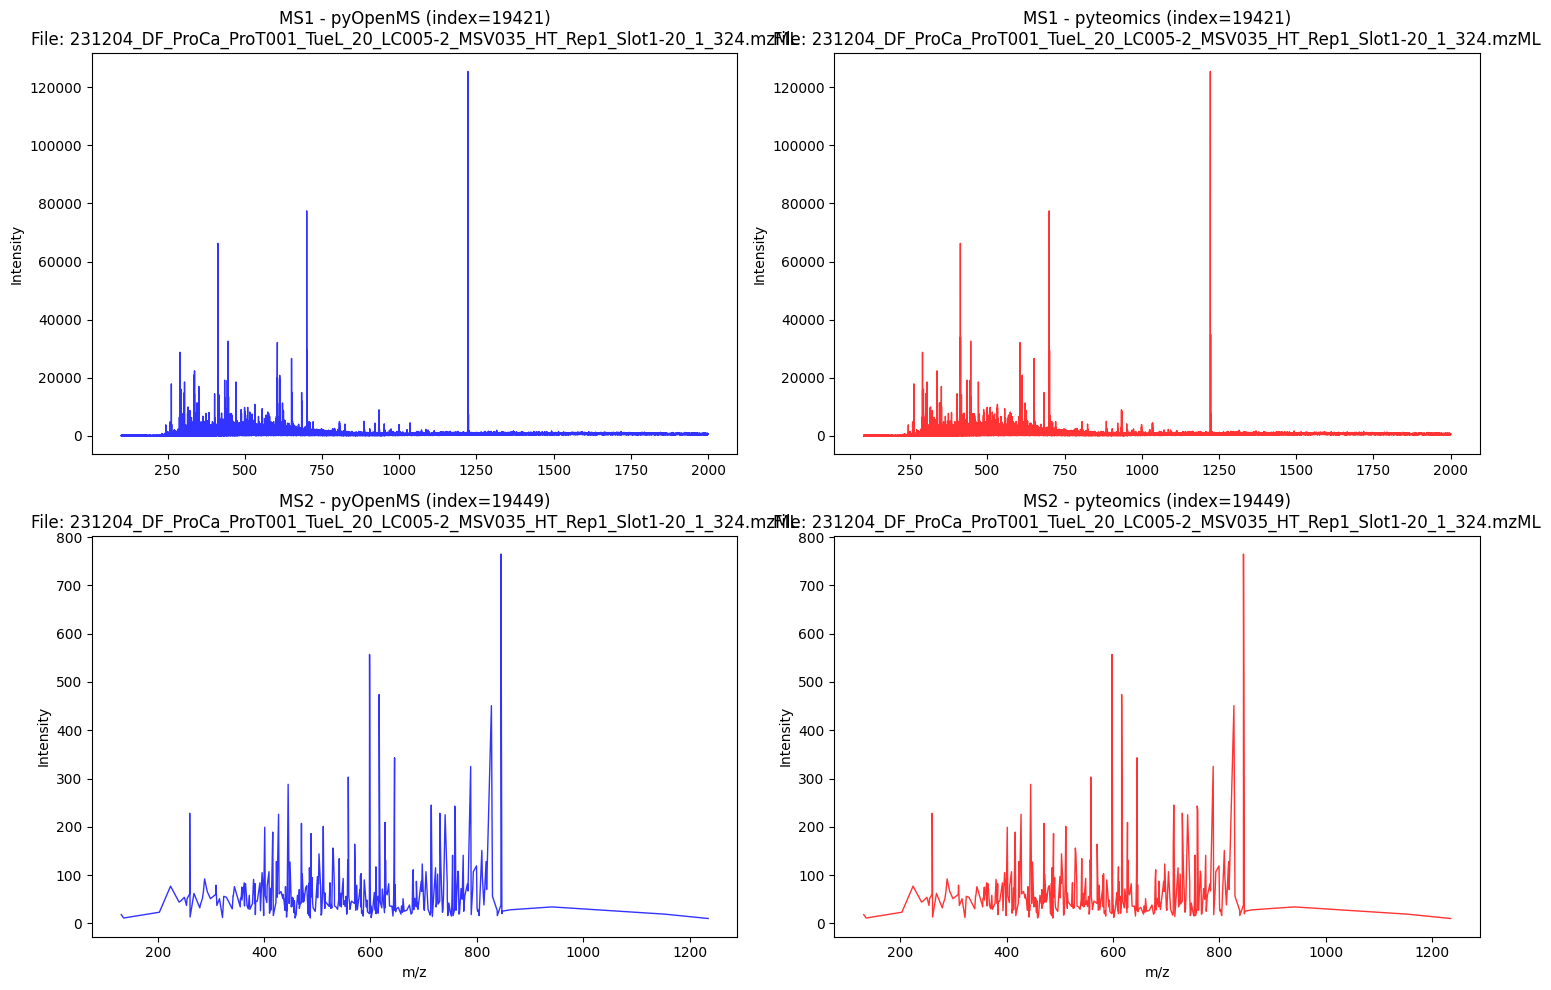

In [7]:
import os
import matplotlib.pyplot as plt
import numpy as np # Ensure numpy is available

# Check if ANALYSIS_BACKEND is defined, default to both if not
if 'ANALYSIS_BACKEND' not in locals():
    ANALYSIS_BACKEND = 'both'

print(f"Running Analysis with Backend: {ANALYSIS_BACKEND.upper()}")

for mzml_file in INPUT_FILES:
    print(f"\n{'='*40}\nProcessing {Path(mzml_file).name}...")
    
    if not os.path.exists(mzml_file):
        print("File not found, skipping.")
        continue
        
    data_openms = {}
    data_pyteomics = {}
    file_name = Path(mzml_file).name
    
    # --- LOAD DATA ---
    try:
        if ANALYSIS_BACKEND.lower() in ['both', 'pyopenms']:
            data_openms = get_data_pyopenms(mzml_file, EFFECTIVE_SPECTRUM_ID)
            
        if ANALYSIS_BACKEND.lower() in ['both', 'pyteomics']:
            data_pyteomics = get_data_pyteomics(mzml_file, EFFECTIVE_SPECTRUM_ID)
            
    except Exception as e:
        print(f"⚠️ Error loading data: {e}")
        continue
        
    # --- PLOT DATA ---
    if ANALYSIS_BACKEND.lower() == 'pyopenms':
        if data_openms:
            plot_spectra(data_openms, 'pyOpenMS', file_name, EFFECTIVE_SPECTRUM_ID)
        else:
            print("No pyOpenMS data loaded.")
            
    elif ANALYSIS_BACKEND.lower() == 'pyteomics':
        if data_pyteomics:
            plot_spectra(data_pyteomics, 'pyteomics', file_name, EFFECTIVE_SPECTRUM_ID)
        else:
            print("No pyteomics data loaded.")
            
    elif ANALYSIS_BACKEND.lower() == 'both':
        if data_openms or data_pyteomics:
            # Comparison stats
            print("--- Comparison Results ---")
            for level in ['MS1', 'MS2']:
                om = data_openms.get(level)
                py = data_pyteomics.get(level)
                if om and py:
                    mz_om, int_om, id_om = om
                    mz_py, int_py, id_py = py
                    match_len = len(mz_om) == len(mz_py)
                    match_val = False
                    if match_len and len(mz_om) > 0:
                        match_val = np.allclose(mz_om, mz_py, atol=1e-4) and np.allclose(int_om, int_py, atol=1e-4)
                    status = "MATCH" if match_len and match_val else f"MISMATCH (Len: {len(mz_om)} vs {len(mz_py)})"
                    print(f"{level}: {status} | IDs: {id_om} vs {id_py}")
                else:
                    print(f"{level}: Data missing in one or both backends.")
            
            plot_spectra_overlay(data_openms, data_pyteomics, file_name)
        else:
            print("No data found for either backend.")
